In [2]:
import numpy as np
from matplotlib import pyplot as plt
# importing tensorflow itself
import tensorflow as tf
# but our way in to tf for beginners is through keras
# sits on top of tf and makes most of what you need available,
# especially if you're not trying to invent new DL methods
from tensorflow import keras
# a couple of helpful things to import 
from sklearn.utils.class_weight import compute_class_weight
#for showing the results
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
from numpy.random import RandomState


In [3]:
from numpy.random import RandomState
import pandas as pd

df = pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/training_set_data_2023_12_13.csv", header=[0], index_col=[0])
rng = RandomState()

train = df.sample(frac=0.7, random_state=rng)
test = df.loc[~df.index.isin(train.index)]

test
train


,1A_01,1A_02,1A_03,1A_04,1A_05,1A_06,1A_07,1A_08,1A_09,1A_10,...,1C_39,1C_40,1C_41,1C_42,1C_43,1C_44,1C_45,1C_46,1C_47,1C_48
var_name,,,,,,,,,,,,,,,,,,,,,
Mar_g16390.t1,9.783776,9.395723,8.584871,8.089230,8.010464,9.481520,9.413737,8.412875,8.949804,9.480707,...,10.087056,11.754972,10.978532,10.412479,10.288850,10.012302,11.839187,9.465202,11.331314,9.784341
Jun_g00772.t1,8.398353,9.147736,9.494558,9.699110,9.774679,9.299058,9.864133,9.583287,10.233457,10.033429,...,10.905503,10.823670,11.416470,10.909421,11.013989,10.565158,10.211251,10.562322,10.577940,10.089670
Sep_g15636.t1,3.167407,2.149315,2.007383,3.424106,2.964033,3.363434,3.384761,5.263420,3.537389,3.362535,...,3.080680,4.226582,5.405196,4.486803,4.905532,5.254732,5.167679,5.197825,5.111247,4.799967
Mar_g12641.t1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.817200,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.422183
Sep_g09227.t1,6.428529,6.987075,6.766128,7.071157,7.011731,7.001570,7.149911,7.456693,7.153898,6.791073,...,6.165630,6.059744,5.754579,6.439747,6.568670,6.447244,6.295457,5.977245,6.036251,6.184438
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Mar_g00980.t1,1.654207,0.585921,1.468625,0.000000,1.390294,0.899397,0.348443,1.165396,0.750120,1.272530,...,0.969382,1.711179,0.848745,1.131421,0.669563,0.000000,0.674452,1.451496,1.095284,1.432836
Jun_g08198.t1,4.363384,4.370931,4.977772,5.218756,6.194506,4.599405,6.126050,5.939903,6.172694,5.809720,...,6.336033,5.940025,6.762691,6.234210,5.763777,5.650272,5.798077,5.704326,5.786587,5.978082
Mar_g07814.t1,1.525599,4.526310,2.271950,1.730787,2.369916,3.471839,1.899893,3.946562,6.083839,2.843631,...,0.712523,0.889751,0.617257,0.375941,0.000000,0.000000,4.120164,2.416107,3.335199,4.571489


In [ ]:
#xdata = pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/training_set_data_2023_12_13.csv", header=[0], index_col=[0])
#ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/training_set_February2024.csv", header=[0], index_col=[0])


xdata = pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/Cyclic_ind_rep_removed.March2024.csv", header=[0], index_col=[0])
ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/Removed_cyclic_ind_cyclic_rep.csv", header=[0], index_col=[0])


np.random.seed(2003)
percentile = .80
rows = np.random.binomial(1, percentile, size=len(xdata)).astype(bool)
print(rows)
x_train = xdata[rows]
x_test = xdata[~rows]
y_train = ydata[rows]
y_test = ydata[~rows]

#ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/training_set_February2024.csv", header=[0], index_col=[0])
#y.index.name = None  # remove index name
#y_train = ydata.sample(frac=0.8, random_state=rng)
#y_test = ydata.loc[~ydata.index.isin(y_train.index)]
#y_train = ydata.loc[xdata.index.isin(x_train.index)]
#y_test = ydata.loc[~xdata.index.isin(x_train.index)]



#x_train.index.name = None  # remove index name
#y_train.index.name = None  # remove index name
#x_test.index.name = None  # remove index name
#x_test.index.name = None  # remove index name

x_train = np.array(x_train)
y_train =  np.array(y_train)

x_test = np.array(x_test)
y_test =  np.array(y_test)


print(len(x_train))
print(len(x_test))
print(len(y_train))
print(len(y_test))

#num_classes = 23
num_classes = 21
input_shape=(96,)

#labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']
labels=['no_expression','no_change','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']



Epoch 1/150
18/18 [==============================] - 0s 5ms/step - loss: 3.0898 - accuracy: 0.0544 - val_loss: 3.0152 - val_accuracy: 0.1250
Epoch 2/150
18/18 [==============================] - 0s 2ms/step - loss: 3.0091 - accuracy: 0.1074 - val_loss: 3.0187 - val_accuracy: 0.0000e+00
Epoch 3/150
18/18 [==============================] - 0s 2ms/step - loss: 2.9738 - accuracy: 0.1117 - val_loss: 2.9707 - val_accuracy: 0.1250
Epoch 4/150
18/18 [==============================] - 0s 2ms/step - loss: 2.9293 - accuracy: 0.1117 - val_loss: 2.9900 - val_accuracy: 0.0000e+00
Epoch 5/150
18/18 [==============================] - 0s 2ms/step - loss: 2.8827 - accuracy: 0.1476 - val_loss: 2.8752 - val_accuracy: 0.2500
Epoch 6/150
18/18 [==============================] - 0s 2ms/step - loss: 2.8400 - accuracy: 0.2049 - val_loss: 2.8231 - val_accuracy: 0.2500
Epoch 7/150
18/18 [==============================] - 0s 2ms/step - loss: 2.7863 - accuracy: 0.2521 - val_loss: 2.6458 - val_accuracy: 0.3750
Epoch

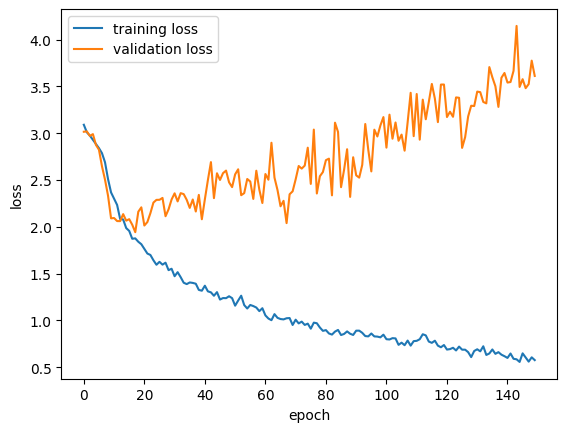

Test accuracy: 0.5691056847572327
12/12 [==============================] - 0s 686us/step


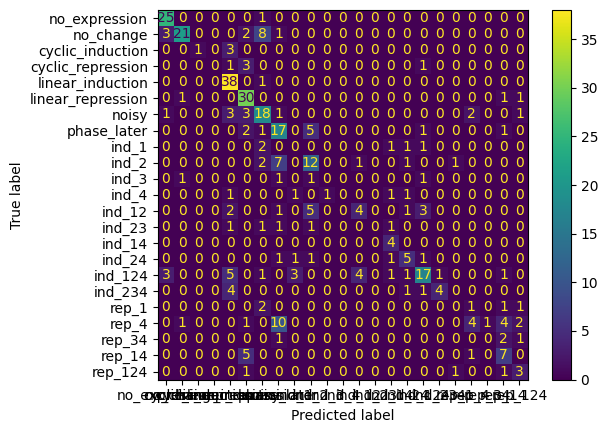

In [92]:
x_train = x_train.reshape(len(x_train), 1, 96)
x_test = x_test.reshape(len(x_test), 1, 96)


from sklearn.utils import compute_class_weight
unique_classes=np.unique(labels)
#class_weight_list = compute_class_weight(class_weight ='balanced', classes=unique_classes, y=labels)

class_weight_list = compute_class_weight(class_weight=None,classes=unique_classes, y=labels)
class_weights = {i: class_weight_list[i] for i in range(len(unique_classes))}

#print(x_train)
model = keras.Sequential(
    [keras.layers.Conv1D(filters=72, kernel_size=16, padding='same', activation='relu', input_shape=(1,96)),
    keras.layers.Flatten(),
        keras.layers.Dense(90, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(60, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(30, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)





model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
out = model.fit(x_train, y_train, batch_size=40, epochs=150, validation_split=0.01,class_weight=class_weights)


plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()
score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])


#labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']
predictions = model.predict(x_test)
cf=confusion_matrix(np.argmax(y_test,axis=1), np.argmax(predictions,axis=1))
ConfusionMatrixDisplay(cf,display_labels=labels).plot()
plt.show()

In [ ]:
model = keras.Sequential(
    [
        # input_shape is the image shape we defined earlier
        keras.Input(shape=input_shape),
        # Flatten doesn't take any arguments here
        keras.layers.Flatten(),
        # Going straight into our output, so one node for each class
        keras.layers.Dense(48, activation="relu"),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

model.fit(x_train, y_train, batch_size=64, epochs=30, validation_split=0.1)

out = model.fit(x_train, y_train, batch_size=64, epochs=30, validation_split=0.1)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        keras.layers.Dense(96, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

out = model.fit(x_train, y_train, batch_size=40, epochs=150, validation_split=0.001)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()
score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])

Epoch 1/150
19/19 [==============================] - 0s 4ms/step - loss: 4.2608 - accuracy: 0.0610 - val_loss: 2.9017 - val_accuracy: 0.0000e+00
Epoch 2/150
19/19 [==============================] - 0s 1ms/step - loss: 3.0833 - accuracy: 0.1409 - val_loss: 3.1841 - val_accuracy: 0.0000e+00
Epoch 3/150
19/19 [==============================] - 0s 1ms/step - loss: 2.9092 - accuracy: 0.1775 - val_loss: 2.9542 - val_accuracy: 0.0000e+00
Epoch 4/150
19/19 [==============================] - 0s 1ms/step - loss: 2.7749 - accuracy: 0.2033 - val_loss: 2.9292 - val_accuracy: 0.0000e+00
Epoch 5/150
19/19 [==============================] - 0s 1ms/step - loss: 2.7071 - accuracy: 0.2534 - val_loss: 2.9314 - val_accuracy: 0.0000e+00
Epoch 6/150
19/19 [==============================] - 0s 1ms/step - loss: 2.6029 - accuracy: 0.2764 - val_loss: 2.9430 - val_accuracy: 0.0000e+00
Epoch 7/150
19/19 [==============================] - 0s 1ms/step - loss: 2.5213 - accuracy: 0.2927 - val_loss: 2.9871 - val_accura

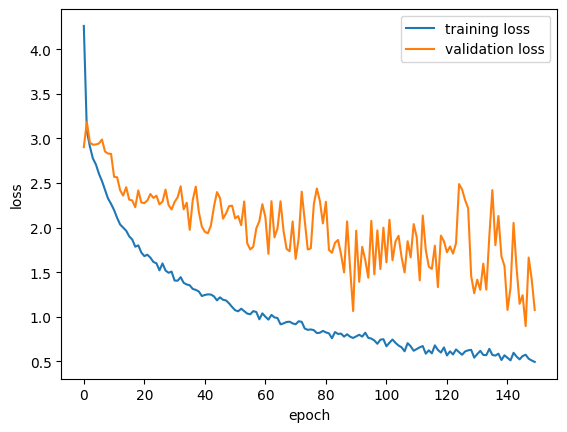

Test accuracy: 0.5384615659713745


In [6]:
model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        keras.layers.Dense(96, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

out = model.fit(x_train, y_train, batch_size=40, epochs=150, validation_split=0.001)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()
score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])

In [ ]:
model = keras.Sequential(
    [
        # input_shape is the image shape we defined earlier
        keras.Input(shape=input_shape),
        # Flatten doesn't take any arguments here
        keras.layers.Flatten(),
        # Going straight into our output, so one node for each class
        keras.layers.Dense(48, activation="relu"),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

model.fit(x_train, y_train, batch_size=64, epochs=30, validation_split=0.1)

out = model.fit(x_train, y_train, batch_size=64, epochs=30, validation_split=0.1)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        keras.layers.Dense(96, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

out = model.fit(x_train, y_train, batch_size=40, epochs=150, validation_split=0.001)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])

Epoch 1/300
19/19 [==============================] - 0s 4ms/step - loss: 3.5723 - accuracy: 0.0705 - val_loss: 3.0961 - val_accuracy: 0.0000e+00
Epoch 2/300
19/19 [==============================] - 0s 1ms/step - loss: 3.0832 - accuracy: 0.0867 - val_loss: 3.1182 - val_accuracy: 0.0000e+00
Epoch 3/300
19/19 [==============================] - 0s 1ms/step - loss: 2.9686 - accuracy: 0.1301 - val_loss: 2.9408 - val_accuracy: 0.0000e+00
Epoch 4/300
19/19 [==============================] - 0s 1ms/step - loss: 2.8765 - accuracy: 0.1612 - val_loss: 2.9544 - val_accuracy: 0.0000e+00
Epoch 5/300
19/19 [==============================] - 0s 1ms/step - loss: 2.7873 - accuracy: 0.1951 - val_loss: 2.8479 - val_accuracy: 0.0000e+00
Epoch 6/300
19/19 [==============================] - 0s 1ms/step - loss: 2.7287 - accuracy: 0.2358 - val_loss: 2.7666 - val_accuracy: 0.0000e+00
Epoch 7/300
19/19 [==============================] - 0s 1ms/step - loss: 2.6603 - accuracy: 0.2778 - val_loss: 2.7564 - val_accura

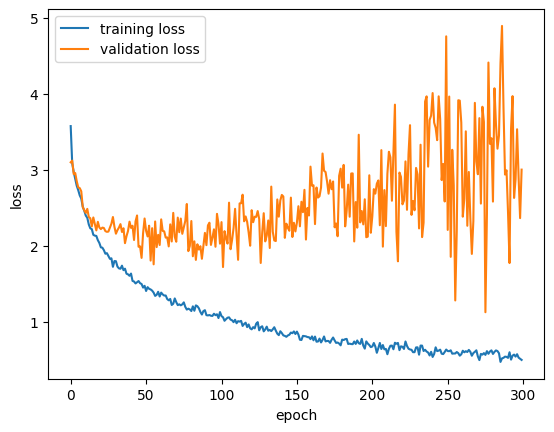

Test accuracy: 0.5769230723381042


In [8]:
model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        keras.layers.Dense(96, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(24, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

out = model.fit(x_train, y_train, batch_size=40, epochs=300, validation_split=0.001)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])

In [ ]:
model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        keras.layers.Dense(96, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

out = model.fit(x_train, y_train, batch_size=40, epochs=200, validation_split=0.001)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()
score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])

In [ ]:
model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        keras.layers.Dense(96, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(60, activation="relu"),
        keras.layers.Dropout(0.10),
        keras.layers.Dense(40, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

out = model.fit(x_train, y_train, batch_size=40, epochs=150, validation_split=0.001)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])

In [111]:
model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        keras.layers.Dense(96, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(60, activation="relu"),
        keras.layers.Dropout(0.10),
        keras.layers.Dense(40, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

out = model.fit(x_train, y_train, batch_size=40, epochs=200, validation_split=0.001)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()
score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])


labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']
predictions = model.predict(x_test)
cf=confusion_matrix(np.argmax(y_test,axis=1), np.argmax(predictions,axis=1))
ConfusionMatrixDisplay(cf,display_labels=labels).plot()
plt.show()

Epoch 1/200


ValueError: in user code:

    File "/Users/paajanep/Library/Python/3.9/lib/python/site-packages/keras/src/engine/training.py", line 1401, in train_function  *
        return step_function(self, iterator)
    File "/Users/paajanep/Library/Python/3.9/lib/python/site-packages/keras/src/engine/training.py", line 1384, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "/Users/paajanep/Library/Python/3.9/lib/python/site-packages/keras/src/engine/training.py", line 1373, in run_step  **
        outputs = model.train_step(data)
    File "/Users/paajanep/Library/Python/3.9/lib/python/site-packages/keras/src/engine/training.py", line 1150, in train_step
        y_pred = self(x, training=True)
    File "/Users/paajanep/Library/Python/3.9/lib/python/site-packages/keras/src/utils/traceback_utils.py", line 70, in error_handler
        raise e.with_traceback(filtered_tb) from None
    File "/Users/paajanep/Library/Python/3.9/lib/python/site-package

In [ ]:
print(input_shape)
#   [   keras.layers.Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(96,1)),
 
model = keras.Sequential(
    [   keras.Input(shape=input_shape),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(48, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

out = model.fit(x_train, y_train, batch_size=40, epochs=300, validation_split=0.001)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()
score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])

In [ ]:
score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])

In [ ]:

labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']
predictions = model.predict(x_test)
cf=confusion_matrix(np.argmax(y_test,axis=1), np.argmax(predictions,axis=1))
ConfusionMatrixDisplay(cf,display_labels=labels).plot()
plt.show()

In [ ]:
labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']

In [ ]:
labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']

from sklearn.utils import compute_class_weight
unique_classes=np.unique(labels)
class_weight_list = compute_class_weight(class_weight ='balanced', classes=unique_classes, y=labels)
class_weights = {i: class_weight_list[i] for i in range(len(unique_classes))}

model = keras.Sequential(
    [   keras.Input(shape=input_shape),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(48, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)


model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

out = model.fit(x_train, y_train, batch_size=40, epochs=130, validation_split=0.001, class_weight=class_weights)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()
score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])



predictions = model.predict(x_test)
cf=confusion_matrix(np.argmax(y_test,axis=1), np.argmax(predictions,axis=1))
ConfusionMatrixDisplay(cf,display_labels=labels).plot()
plt.show()

In [89]:
import numpy as np
from matplotlib import pyplot as plt
# importing tensorflow itself
import tensorflow as tf
# but our way in to tf for beginners is through keras
# sits on top of tf and makes most of what you need available,
# especially if you're not trying to invent new DL methods
from tensorflow import keras
# a couple of helpful things to import 
from sklearn.utils.class_weight import compute_class_weight
#for showing the results
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
from numpy.random import RandomState

xdata = pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/training_set_data_March2024.sorted.csv", header=[0], index_col=[0])
ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/training_set_March_2024.sorted.csv", header=[0], index_col=[0])

np.random.seed(2024)
percentile = .66
rows = np.random.binomial(1, percentile, size=len(xdata)).astype(bool)
print(rows)
x_train = xdata[rows]
x_test = xdata[~rows]
y_train = ydata[rows]
y_test = ydata[~rows]

x_train = np.array(x_train)
y_train =  np.array(y_train)

x_test = np.array(x_test)
y_test =  np.array(y_test)


print(len(x_train))
print(len(x_test))
print(len(y_train))
print(len(y_test))

num_classes = 23
input_shape=(96,)



labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']

from sklearn.utils import compute_class_weight
unique_classes=np.unique(labels)
class_weight_list = compute_class_weight(class_weight ='balanced', classes=unique_classes, y=labels)
class_weights = {i: class_weight_list[i] for i in range(len(unique_classes))}


model = keras.Sequential(
    [Conv1D(filters=256, kernel_size=5, padding='same', activation='relu', input_shape=(1,input_shape)),
    Flatten(),
        keras.layers.Dense(96, activation="relu"),
        keras.layers.Dropout(0.10),
        keras.layers.Dense(48, activation="relu"),
        keras.layers.Dropout(0.10),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

out = model.fit(x_train, y_train, batch_size=40, epochs=150, validation_split=0.001,class_weight=class_weights)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()
score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])


labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']
predictions = model.predict(x_test)
cf=confusion_matrix(np.argmax(y_test,axis=1), np.argmax(predictions,axis=1))
ConfusionMatrixDisplay(cf,display_labels=labels).plot()
plt.show()

[ True False  True ...  True False  True]
706
369
706
369


TypeError: Dimension value must be integer or None or have an __index__ method, got value '(96,)' with type '<class 'tuple'>'

In [22]:
X_train = np.array([[-1.0,-1.0], [1.0, -1.0], [1.0,1.0]])
y_train = np.array([[1.0], [-1.0], [0.0]])

X_test = np.array([[1.0,-1.0], [1.0, -1.0]])
y_test = np.array([[1.0], [-1.0]])

features_count = 2

print(X_train.shape[0])
print(X_train.shape[1])

X_train = X_train.reshape(X_train.shape[0], 1, X_train.shape[1])
X_test = X_test.reshape(X_test.shape[0], 1, X_test.shape[1])


3
2


In [46]:
from keras.models import Sequential
from keras.layers import Dense, Conv1D, Activation, Flatten
import numpy as np
X_train = np.array([[-1.0,-1.0], [1.0, -1.0], [1.0,1.0]])
y_train = np.array([[1.0], [-1.0], [0.0]])

X_test = np.array([[1.0,-1.0], [1.0, -1.0]])
y_test = np.array([[1.0], [-1.0]])

features_count = 2

model = Sequential([
    Conv1D(filters=256, kernel_size=5, padding='same', activation='relu', input_shape=(1,features_count)),
    Flatten(),
    Dense(64),
    Activation('relu'),
    Dense(32),
    Activation('softmax'),
    Dense(1),
])

X_train = X_train.reshape(X_train.shape[0], 1, X_train.shape[1])
X_test = X_test.reshape(X_test.shape[0], 1, X_test.shape[1])

model.compile(optimizer="adam", loss='mse')
model.fit(X_train, y_train, epochs=10, batch_size=1, verbose=1)
model.evaluate(X_test, y_test, batch_size=1)

Epoch 1/10
3/3 [==============================] - 0s 2ms/step - loss: 0.6724
Epoch 2/10
3/3 [==============================] - 0s 1ms/step - loss: 0.6680
Epoch 3/10
3/3 [==============================] - 0s 1ms/step - loss: 0.6651
Epoch 4/10
3/3 [==============================] - 0s 2ms/step - loss: 0.6629
Epoch 5/10
3/3 [==============================] - 0s 1ms/step - loss: 0.6588
Epoch 6/10
3/3 [==============================] - 0s 1ms/step - loss: 0.6561
Epoch 7/10
3/3 [==============================] - 0s 1ms/step - loss: 0.6518
Epoch 8/10
3/3 [==============================] - 0s 1ms/step - loss: 0.6467
Epoch 9/10
3/3 [==============================] - 0s 1ms/step - loss: 0.6423
Epoch 10/10
2/2 [==============================] - 0s 2ms/step - loss: 1.0007


1.0006544589996338

In [98]:
xdata = pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/training_set_data_March2024.sorted.csv", header=[0], index_col=[0])
ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/IND_RED_collapsed.classes_Mar190324.sorted.csv", header=[0], index_col=[0])


#xdata = pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/Cyclic_ind_rep_removed.March2024.csv", header=[0], index_col=[0])
#ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/Removed_cyclic_ind_cyclic_rep.csv", header=[0], index_col=[0])


np.random.seed(2003)
percentile = .80
rows = np.random.binomial(1, percentile, size=len(xdata)).astype(bool)
print(rows)
x_train = xdata[rows]
x_test = xdata[~rows]
y_train = ydata[rows]
y_test = ydata[~rows]

#ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/training_set_February2024.csv", header=[0], index_col=[0])
#y.index.name = None  # remove index name
#y_train = ydata.sample(frac=0.8, random_state=rng)
#y_test = ydata.loc[~ydata.index.isin(y_train.index)]
#y_train = ydata.loc[xdata.index.isin(x_train.index)]
#y_test = ydata.loc[~xdata.index.isin(x_train.index)]



#x_train.index.name = None  # remove index name
#y_train.index.name = None  # remove index name
#x_test.index.name = None  # remove index name
#x_test.index.name = None  # remove index name

x_train = np.array(x_train)
y_train =  np.array(y_train)

x_test = np.array(x_test)
y_test =  np.array(y_test)


print(len(x_train))
print(len(x_test))
print(len(y_train))
print(len(y_test))

#num_classes = 23
num_classes = 10
input_shape=(96,)

#labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']
labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind','rep']



[ True  True  True ...  True False  True]
847
228
847
228


Epoch 1/100
22/22 [==============================] - 0s 5ms/step - loss: 2.1447 - accuracy: 0.2754 - val_loss: 2.2883 - val_accuracy: 0.0000e+00
Epoch 2/100
22/22 [==============================] - 0s 2ms/step - loss: 1.9564 - accuracy: 0.3310 - val_loss: 2.3606 - val_accuracy: 0.0000e+00
Epoch 3/100
22/22 [==============================] - 0s 2ms/step - loss: 1.8046 - accuracy: 0.3723 - val_loss: 2.3357 - val_accuracy: 0.0000e+00
Epoch 4/100
22/22 [==============================] - 0s 2ms/step - loss: 1.7022 - accuracy: 0.3983 - val_loss: 2.4647 - val_accuracy: 0.0000e+00
Epoch 5/100
22/22 [==============================] - 0s 2ms/step - loss: 1.6633 - accuracy: 0.3865 - val_loss: 2.5646 - val_accuracy: 0.0000e+00
Epoch 6/100
22/22 [==============================] - 0s 2ms/step - loss: 1.5707 - accuracy: 0.4184 - val_loss: 2.3650 - val_accuracy: 0.0000e+00
Epoch 7/100
22/22 [==============================] - 0s 2ms/step - loss: 1.4885 - accuracy: 0.4444 - val_loss: 2.4887 - val_accura

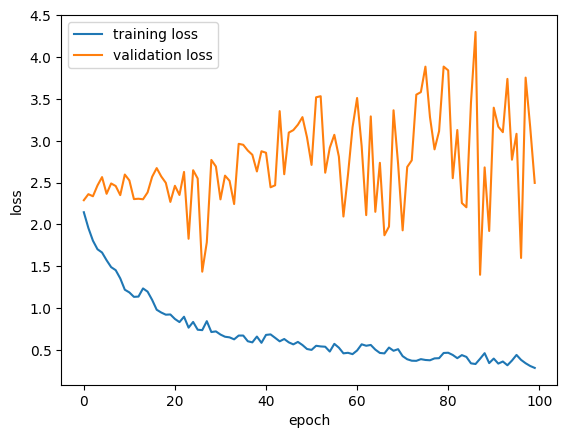

Test accuracy: 0.6973684430122375
8/8 [==============================] - 0s 639us/step


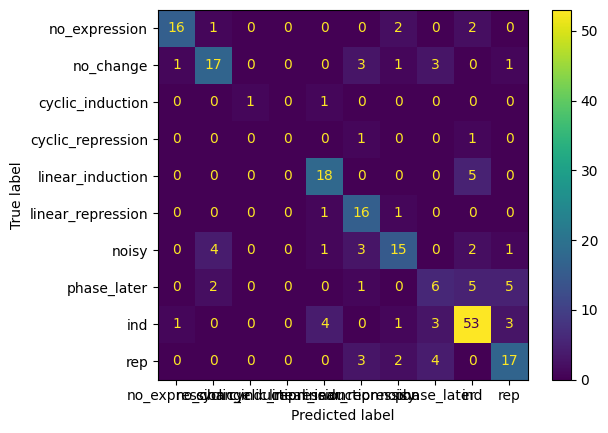

In [101]:
x_train = x_train.reshape(len(x_train), 1, 96)
x_test = x_test.reshape(len(x_test), 1, 96)


from sklearn.utils import compute_class_weight
unique_classes=np.unique(labels)
#class_weight_list = compute_class_weight(class_weight ='balanced', classes=unique_classes, y=labels)

class_weight_list = compute_class_weight(class_weight=None,classes=unique_classes, y=labels)
class_weights = {i: class_weight_list[i] for i in range(len(unique_classes))}

#print(x_train)
model = keras.Sequential(
    [keras.layers.Conv1D(filters=72, kernel_size=16, padding='same', activation='relu', input_shape=(1,96)),
    keras.layers.Flatten(),
        keras.layers.Dense(90, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(60, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(30, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)





model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
out = model.fit(x_train, y_train, batch_size=40, epochs=100, validation_split=0.001,class_weight=class_weights)


plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()
score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])


#labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']
predictions = model.predict(x_test)
cf=confusion_matrix(np.argmax(y_test,axis=1), np.argmax(predictions,axis=1))
ConfusionMatrixDisplay(cf,display_labels=labels).plot()
plt.show()

In [19]:
xdata = pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/training_set_data_March2024.sorted.csv", header=[0], index_col=[0])
ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/IND_RED_CYCLIC_collapsed.classesMar190324.sorted.csv", header=[0], index_col=[0])


#xdata = pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/Cyclic_ind_rep_removed.March2024.csv", header=[0], index_col=[0])
#ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/Removed_cyclic_ind_cyclic_rep.csv", header=[0], index_col=[0])


np.random.seed(2003)
percentile = .8
rows = np.random.binomial(1, percentile, size=len(xdata)).astype(bool)
print(rows)
x_train = xdata[rows]
x_test = xdata[~rows]
y_train = ydata[rows]
y_test = ydata[~rows]

#ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/training_set_February2024.csv", header=[0], index_col=[0])
#y.index.name = None  # remove index name
#y_train = ydata.sample(frac=0.8, random_state=rng)
#y_test = ydata.loc[~ydata.index.isin(y_train.index)]
#y_train = ydata.loc[xdata.index.isin(x_train.index)]
#y_test = ydata.loc[~xdata.index.isin(x_train.index)]



#x_train.index.name = None  # remove index name
#y_train.index.name = None  # remove index name
#x_test.index.name = None  # remove index name
#x_test.index.name = None  # remove index name

x_train = np.array(x_train)
y_train =  np.array(y_train)

x_test = np.array(x_test)
y_test =  np.array(y_test)


print(len(x_train))
print(len(x_test))
print(len(y_train))
print(len(y_test))

#num_classes = 23
num_classes = 8
input_shape=(96,)

#labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']
labels=['no_expression','no_change','linear_induction','linear_repression','noisy','phase_later','ind','rep']



[ True  True  True ...  True False  True]
847
228
847
228


In [18]:


from sklearn.utils import compute_class_weight
unique_classes=np.unique(labels)
#class_weight_list = compute_class_weight(class_weight ='balanced', classes=unique_classes, y=labels)

class_weight_list = compute_class_weight(class_weight=None,classes=unique_classes, y=labels)
class_weights = {i: class_weight_list[i] for i in range(len(unique_classes))}

model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        keras.layers.Dense(96, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)


model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

out = model.fit(x_train, y_train, batch_size=40, epochs=150, validation_split=0.001)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

predictions = model.predict(x_test)
cf=confusion_matrix(np.argmax(y_test,axis=1), np.argmax(predictions,axis=1))
ConfusionMatrixDisplay(cf,display_labels=labels).plot()
plt.show()

score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])


x_train = x_train.reshape(len(x_train), 1, 96)
x_test = x_test.reshape(len(x_test), 1, 96)


#print(x_train)
model = keras.Sequential(
    [keras.layers.Conv1D(filters=72, kernel_size=16, padding='same', activation='relu', input_shape=(1,96)),
    keras.layers.Flatten(),
        keras.layers.Dense(96, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(4, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(30, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)





model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
out = model.fit(x_train, y_train, batch_size=40, epochs=100, validation_split=0.001,class_weight=class_weights)


plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()
score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])


#labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']
predictions = model.predict(x_test)
cf=confusion_matrix(np.argmax(y_test,axis=1), np.argmax(predictions,axis=1))
ConfusionMatrixDisplay(cf,display_labels=labels).plot()
plt.show()

Epoch 1/150


ValueError: in user code:

    File "/Users/paajanep/Library/Python/3.9/lib/python/site-packages/keras/src/engine/training.py", line 1401, in train_function  *
        return step_function(self, iterator)
    File "/Users/paajanep/Library/Python/3.9/lib/python/site-packages/keras/src/engine/training.py", line 1384, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "/Users/paajanep/Library/Python/3.9/lib/python/site-packages/keras/src/engine/training.py", line 1373, in run_step  **
        outputs = model.train_step(data)
    File "/Users/paajanep/Library/Python/3.9/lib/python/site-packages/keras/src/engine/training.py", line 1150, in train_step
        y_pred = self(x, training=True)
    File "/Users/paajanep/Library/Python/3.9/lib/python/site-packages/keras/src/utils/traceback_utils.py", line 70, in error_handler
        raise e.with_traceback(filtered_tb) from None
    File "/Users/paajanep/Library/Python/3.9/lib/python/site-package

[ True  True  True ... False False  True]
626
449
626
449
Epoch 1/40
63/63 [==============================] - 0s 2ms/step - loss: 2.0343 - accuracy: 0.2878 - val_loss: 2.1906 - val_accuracy: 0.2500
Epoch 2/40
63/63 [==============================] - 0s 772us/step - loss: 1.6881 - accuracy: 0.3617 - val_loss: 1.9191 - val_accuracy: 0.5000
Epoch 3/40
63/63 [==============================] - 0s 752us/step - loss: 1.4563 - accuracy: 0.4309 - val_loss: 2.0293 - val_accuracy: 0.0000e+00
Epoch 4/40
63/63 [==============================] - 0s 774us/step - loss: 1.4115 - accuracy: 0.4904 - val_loss: 1.8176 - val_accuracy: 0.5000
Epoch 5/40
63/63 [==============================] - 0s 753us/step - loss: 1.2932 - accuracy: 0.5305 - val_loss: 1.8031 - val_accuracy: 0.5000
Epoch 6/40
63/63 [==============================] - 0s 778us/step - loss: 1.2141 - accuracy: 0.5691 - val_loss: 1.7270 - val_accuracy: 0.2500
Epoch 7/40
63/63 [==============================] - 0s 836us/step - loss: 1.1806 - accur

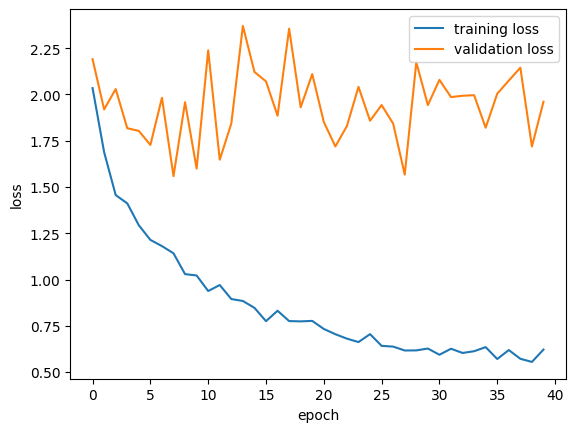

15/15 [==============================] - 0s 503us/step


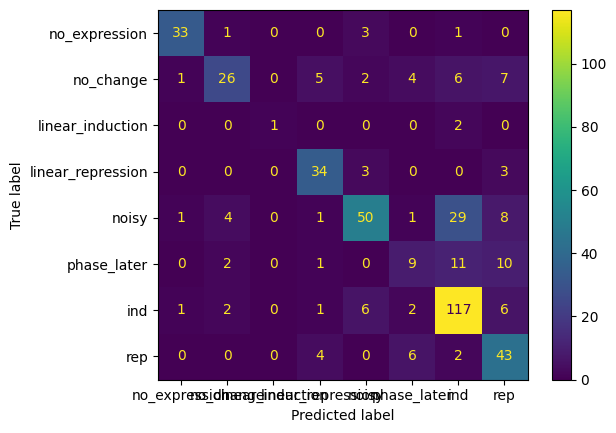

Test accuracy: 0.6971046924591064
Epoch 1/40
16/16 [==============================] - 0s 6ms/step - loss: 1.9696 - accuracy: 0.2588 - val_loss: 1.9228 - val_accuracy: 0.0000e+00
Epoch 2/40
16/16 [==============================] - 0s 2ms/step - loss: 1.8505 - accuracy: 0.3457 - val_loss: 1.9139 - val_accuracy: 0.5000
Epoch 3/40
16/16 [==============================] - 0s 2ms/step - loss: 1.7319 - accuracy: 0.4116 - val_loss: 1.8345 - val_accuracy: 0.5000
Epoch 4/40
16/16 [==============================] - 0s 2ms/step - loss: 1.6475 - accuracy: 0.4244 - val_loss: 1.6762 - val_accuracy: 0.7500
Epoch 5/40
16/16 [==============================] - 0s 2ms/step - loss: 1.5301 - accuracy: 0.4727 - val_loss: 1.8329 - val_accuracy: 0.2500
Epoch 6/40
16/16 [==============================] - 0s 2ms/step - loss: 1.4711 - accuracy: 0.4887 - val_loss: 1.8020 - val_accuracy: 0.5000
Epoch 7/40
16/16 [==============================] - 0s 2ms/step - loss: 1.3705 - accuracy: 0.5080 - val_loss: 1.9345 - val

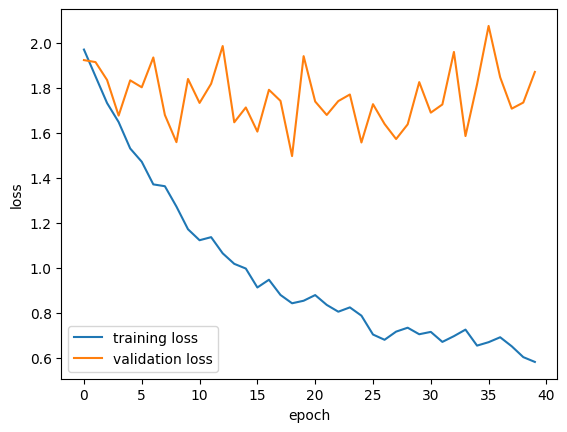

Test accuracy: 0.6948775053024292
15/15 [==============================] - 0s 589us/step


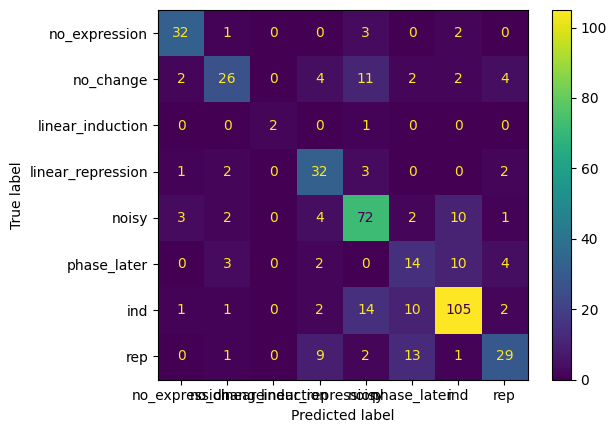

In [35]:
xdata = pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/training_set_data_March2024.sorted.csv", header=[0], index_col=[0])
ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/IND_RED_CYCLIC_collapsed.classesMar190324.sorted.csv", header=[0], index_col=[0])


#xdata = pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/Cyclic_ind_rep_removed.March2024.csv", header=[0], index_col=[0])
#ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/Removed_cyclic_ind_cyclic_rep.csv", header=[0], index_col=[0])


np.random.seed(2003)
percentile = .6
rows = np.random.binomial(1, percentile, size=len(xdata)).astype(bool)
print(rows)
x_train = xdata[rows]
x_test = xdata[~rows]
y_train = ydata[rows]
y_test = ydata[~rows]

#ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/training_set_February2024.csv", header=[0], index_col=[0])
#y.index.name = None  # remove index name
#y_train = ydata.sample(frac=0.8, random_state=rng)
#y_test = ydata.loc[~ydata.index.isin(y_train.index)]
#y_train = ydata.loc[xdata.index.isin(x_train.index)]
#y_test = ydata.loc[~xdata.index.isin(x_train.index)]



#x_train.index.name = None  # remove index name
#y_train.index.name = None  # remove index name
#x_test.index.name = None  # remove index name
#x_test.index.name = None  # remove index name

x_train = np.array(x_train)
y_train =  np.array(y_train)

x_test = np.array(x_test)
y_test =  np.array(y_test)


print(len(x_train))
print(len(x_test))
print(len(y_train))
print(len(y_test))

#num_classes = 23
num_classes = 8
input_shape=(96,)

#labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']
labels=['no_expression','no_change','linear_induction','linear_repression','noisy','phase_later','ind','rep']

from sklearn.utils import compute_class_weight
unique_classes=np.unique(labels)
class_weight_list = compute_class_weight(class_weight ='balanced', classes=unique_classes, y=labels)

class_weight_list = compute_class_weight(class_weight=None,classes=unique_classes, y=labels)
class_weights = {i: class_weight_list[i] for i in range(len(unique_classes))}

model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        keras.layers.Dense(96, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(20, activation="relu"),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)


model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

out = model.fit(x_train, y_train, batch_size=10, epochs=40, validation_split=0.005,class_weight=class_weights)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

predictions = model.predict(x_test)
cf=confusion_matrix(np.argmax(y_test,axis=1), np.argmax(predictions,axis=1))
ConfusionMatrixDisplay(cf,display_labels=labels).plot()
plt.show()

score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])


x_train = x_train.reshape(len(x_train), 1, 96)
x_test = x_test.reshape(len(x_test), 1, 96)


#print(x_train)
model = keras.Sequential(
    [keras.layers.Conv1D(filters=72, kernel_size=16, padding='same', activation='relu', input_shape=(1,96)),
    keras.layers.Flatten(),
        keras.layers.Dense(96, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(20, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)





model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
out = model.fit(x_train, y_train, batch_size=40, epochs=40, validation_split=0.005,class_weight=class_weights)


plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()
score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])


#labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']
predictions = model.predict(x_test)
cf=confusion_matrix(np.argmax(y_test,axis=1), np.argmax(predictions,axis=1))
ConfusionMatrixDisplay(cf,display_labels=labels).plot()
plt.show()

[ True  True  True  True False  True False False False  True False  True
  True  True  True False False  True False False  True  True  True False
 False  True False False False False  True  True  True False  True  True
 False  True False  True False  True  True False False  True False False
  True  True False False  True  True  True False False  True  True  True
  True False  True  True  True False  True  True False  True False  True
 False  True  True  True  True  True False  True  True  True  True  True
  True  True  True  True False  True  True  True  True  True False False
  True  True  True  True  True  True  True False  True  True  True  True
  True  True False  True  True False  True  True  True  True False  True
 False  True False  True  True  True False  True  True  True False  True
  True False  True  True  True False False False False False  True  True
 False False  True False False  True  True  True  True False False False
  True  True  True  True  True  True False False  T

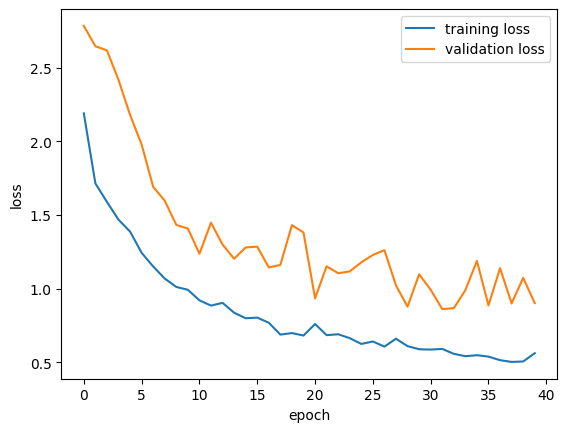

10/10 [==============================] - 0s 575us/step


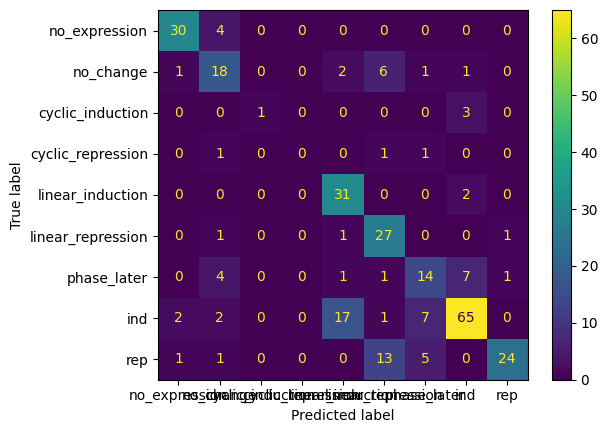

Test accuracy: 0.7023411393165588
Epoch 1/60
17/17 [==============================] - 0s 5ms/step - loss: 1.9633 - accuracy: 0.3185 - val_loss: 2.4004 - val_accuracy: 0.0000e+00
Epoch 2/60
17/17 [==============================] - 0s 2ms/step - loss: 1.8286 - accuracy: 0.3333 - val_loss: 2.4063 - val_accuracy: 0.0000e+00
Epoch 3/60
17/17 [==============================] - 0s 2ms/step - loss: 1.7592 - accuracy: 0.3586 - val_loss: 2.3841 - val_accuracy: 0.0000e+00
Epoch 4/60
17/17 [==============================] - 0s 2ms/step - loss: 1.6639 - accuracy: 0.4033 - val_loss: 2.2958 - val_accuracy: 0.2500
Epoch 5/60
17/17 [==============================] - 0s 2ms/step - loss: 1.5408 - accuracy: 0.4315 - val_loss: 2.3135 - val_accuracy: 0.5000
Epoch 6/60
17/17 [==============================] - 0s 2ms/step - loss: 1.4575 - accuracy: 0.4777 - val_loss: 2.2927 - val_accuracy: 0.5000
Epoch 7/60
17/17 [==============================] - 0s 2ms/step - loss: 1.3527 - accuracy: 0.5476 - val_loss: 2.23

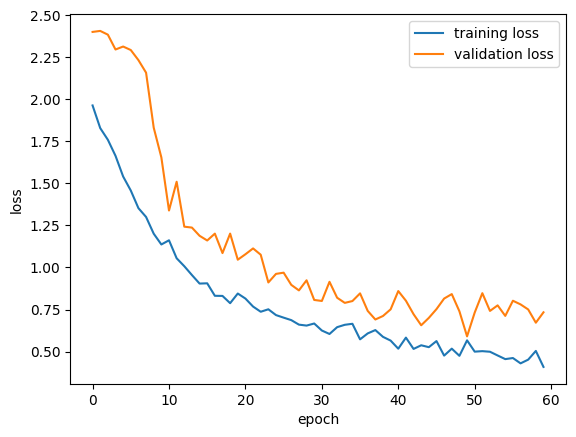

Test accuracy: 0.7458193898200989
10/10 [==============================] - 0s 577us/step
[[8.5183711e-07 4.9037073e-05 1.1348837e-04 ... 2.6462829e-02
  9.7157425e-01 2.3333050e-04]
 [5.2092090e-04 8.0596912e-01 8.0532557e-04 ... 8.1648141e-02
  3.7117306e-02 5.2938112e-03]
 [2.8357748e-05 3.2534560e-03 1.0918371e-05 ... 4.9766698e-01
  3.3907917e-01 1.5967771e-01]
 ...
 [1.2552794e-05 1.7866805e-02 2.0892930e-06 ... 4.0469643e-02
  4.7558965e-04 2.1193346e-02]
 [4.1889196e-04 5.8655590e-02 6.7536748e-05 ... 1.7468935e-01
  1.2939687e-02 3.2327753e-01]
 [3.6377758e-03 1.6570655e-01 2.0779524e-04 ... 8.9667961e-02
  1.3535338e-02 1.4425318e-01]]


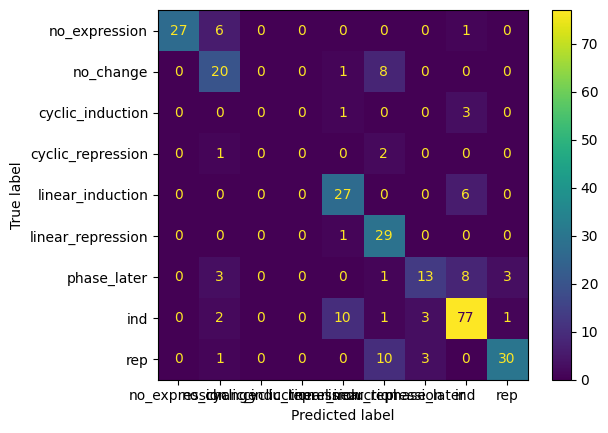

4069/4069 [==============================] - 2s 419us/step
[[2.6687467e-04 4.0136236e-01 1.9665256e-04 ... 1.4886498e-01
  9.1962516e-03 5.8601744e-02]
 [2.3473047e-03 7.7386898e-01 2.6430536e-04 ... 1.1919148e-01
  1.5221941e-02 5.6104876e-02]
 [1.2213870e-02 7.9493546e-01 3.0847813e-04 ... 6.4778879e-02
  1.4824703e-02 5.4977857e-02]
 ...
 [9.9999893e-01 5.2398782e-08 1.1978864e-10 ... 2.0815611e-07
  7.8685662e-07 1.4008820e-07]
 [1.6741518e-05 2.1385178e-02 2.5793072e-06 ... 4.6387147e-02
  5.6415529e-04 2.7779426e-02]
 [1.3990772e-02 8.0861098e-01 2.8968451e-03 ... 2.8657584e-02
  9.1741882e-02 3.8114747e-03]]


In [5]:
#xdata = pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/training_set_data_April2024.sorted.csv", header=[0], index_col=[0])
#ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/IND_RED_CYCLIC_without_noisy_collapsed.classes_Apr120424.sorted.txt", header=[0], index_col=[0])
xdata = pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/training_set_data_April2024.sorted.csv", header=[0], index_col=[0])
ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/IND_RED_without_noisy_collapsed.classes_Apr120424.sorted.txt", header=[0], index_col=[0])


#xdata = pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/Cyclic_ind_rep_removed.March2024.csv", header=[0], index_col=[0])
#ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/Removed_cyclic_ind_cyclic_rep.csv", header=[0], index_col=[0])


np.random.seed(2003)
percentile = .7
rows = np.random.binomial(1, percentile, size=len(xdata)).astype(bool)
print(rows)
x_train = xdata[rows]
x_test = xdata[~rows]
y_train = ydata[rows]
y_test = ydata[~rows]

#ydata= pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/data/training_set_February2024.csv", header=[0], index_col=[0])
#y.index.name = None  # remove index name
#y_train = ydata.sample(frac=0.8, random_state=rng)
#y_test = ydata.loc[~ydata.index.isin(y_train.index)]
#y_train = ydata.loc[xdata.index.isin(x_train.index)]
#y_test = ydata.loc[~xdata.index.isin(x_train.index)]



#x_train.index.name = None  # remove index name
#y_train.index.name = None  # remove index name
#x_test.index.name = None  # remove index name
#x_test.index.name = None  # remove index name

x_train = np.array(x_train)
y_train =  np.array(y_train)

x_test = np.array(x_test)
y_test =  np.array(y_test)


print(len(x_train))
print(len(x_test))
print(len(y_train))
print(len(y_test))

#num_classes = 23
num_classes = 9
input_shape=(96,)

#labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']
labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','phase_later','ind','rep']

from sklearn.utils import compute_class_weight
unique_classes=np.unique(labels)
class_weight_list = compute_class_weight(class_weight ='balanced', classes=unique_classes, y=labels)

class_weight_list = compute_class_weight(class_weight=None,classes=unique_classes, y=labels)
class_weights = {i: class_weight_list[i] for i in range(len(unique_classes))}

model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        keras.layers.Dense(96, activation="relu"),
        keras.layers.Dropout(0.15),
        keras.layers.Dense(20, activation="relu"),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)


model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

out = model.fit(x_train, y_train, batch_size=10, epochs=40, validation_split=0.005,class_weight=class_weights)

plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

predictions = model.predict(x_test)
cf=confusion_matrix(np.argmax(y_test,axis=1), np.argmax(predictions,axis=1))
ConfusionMatrixDisplay(cf,display_labels=labels).plot()
plt.show()

score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])


x_train = x_train.reshape(len(x_train), 1, 96)
x_test = x_test.reshape(len(x_test), 1, 96)


#print(x_train)
model = keras.Sequential(
    [keras.layers.Conv1D(filters=72, kernel_size=16, padding='same', activation='relu', input_shape=(1,96)),
    keras.layers.Flatten(),
        keras.layers.Dense(96, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(30, activation="relu"),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)





model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
out = model.fit(x_train, y_train, batch_size=40, epochs=60, validation_split=0.005,class_weight=class_weights)


plt.plot(out.history['loss'])
plt.plot(out.history['val_loss'])
plt.legend(['training loss','validation loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.savefig("model_convergence.pdf", format="pdf", bbox_inches="tight")
plt.show()
plt.show()
score = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", score[1])


#labels=['no_expression','no_change','cyclic_induction','cyclic_repression','linear_induction','linear_repression','noisy','phase_later','ind_1','ind_2','ind_3','ind_4','ind_12','ind_23','ind_14','ind_24','ind_124','ind_234','rep_1','rep_4','rep_34','rep_14','rep_124']
predictions = model.predict(x_test)
print(predictions)
np.savetxt('test.out', predictions, delimiter=',') 

cf=confusion_matrix(np.argmax(y_test,axis=1), np.argmax(predictions,axis=1))
ConfusionMatrixDisplay(cf,display_labels=labels).plot()
plt.savefig("confusion_matrix.pdf", format="pdf", bbox_inches="tight")
plt.show()

full_data = pd.read_csv("/Users/paajanep/Documents/Collaborations/Antony-Dodd/R-project/full_data_set_2024_04_23.csv", header=[0], index_col=[0])
full_data_array = np.array(full_data)
full_data_array = full_data_array.reshape(len(full_data_array), 1, 96)

predictions_full = model.predict(full_data_array)
print(predictions_full)
np.savetxt('predictions_full_2024_04_24.csv', predictions_full, delimiter=',') 
predicted_classes = np.argmax(predictions_full,axis=1)
np.savetxt('predictions_full_max_2024_04_24.csv', predicted_classes, delimiter=',') 
